# Taxas de Juros

A API de taxas de juros de operações de crédito pode ser acessada através da classe `bcb.TaxaJuros`.

Os dados são obtidos a partir da [API de Taxas de Juros](https://olinda.bcb.gov.br/olinda/servico/taxaJuros/versao/v2/documentacao).

Esta API usa o serviço `taxaJuros` versão `v2`. O método `describe` mostra os `EntitySets` e suas propriedades:

In [1]:
from bcb import TaxaJuros
em = TaxaJuros()
em.describe()

EntitySets:

EntitySet (Endpoint): TaxasJurosMensalPorMes
EntityType: br.gov.bcb.olinda.servico.taxaJuros.TaxaJurosMensal
Properties: Mes<str>, Modalidade<str>, Posicao<int>, InstituicaoFinanceira<str>, TaxaJurosAoMes<float>, TaxaJurosAoAno<float>, cnpj8<str>, anoMes<str>

EntitySet (Endpoint): ParametrosConsulta
EntityType: br.gov.bcb.olinda.servico.taxaJuros.ParametrosConsulta
Properties: codigoSegmento<str>, segmento<str>, codigoModalidade<str>, modalidade<str>, tipoModalidade<str>

EntitySet (Endpoint): TaxasJurosDiariaPorInicioPeriodo
EntityType: br.gov.bcb.olinda.servico.taxaJuros.TaxaJurosDiaria
Properties: InicioPeriodo<str>, FimPeriodo<str>, codigoSegmento<str>, Segmento<str>, codigoModalidade<str>, Modalidade<str>, Posicao<int>, InstituicaoFinanceira<str>, TaxaJurosAoMes<float>, TaxaJurosAoAno<float>, cnpj8<str>

EntitySet (Endpoint): ConsultaUnificada
EntityType: br.gov.bcb.olinda.servico.taxaJuros.TaxaJurosDiaria
Properties: InicioPeriodo<str>, FimPeriodo<str>, codigoSegmen

Para restringir a saída a um `EntitySet` específico, informe o seu nome:

In [2]:
em.describe("TaxasJurosDiariaPorInicioPeriodo")


EntitySet (Endpoint): TaxasJurosDiariaPorInicioPeriodo
EntityType: br.gov.bcb.olinda.servico.taxaJuros.TaxaJurosDiaria
Properties: InicioPeriodo<str>, FimPeriodo<str>, codigoSegmento<str>, Segmento<str>, codigoModalidade<str>, Modalidade<str>, Posicao<int>, InstituicaoFinanceira<str>, TaxaJurosAoMes<float>, TaxaJurosAoAno<float>, cnpj8<str>


Vejamos um gráfico da mediana das taxas de juros do cheque especial praticada pelas instituições financeiras.

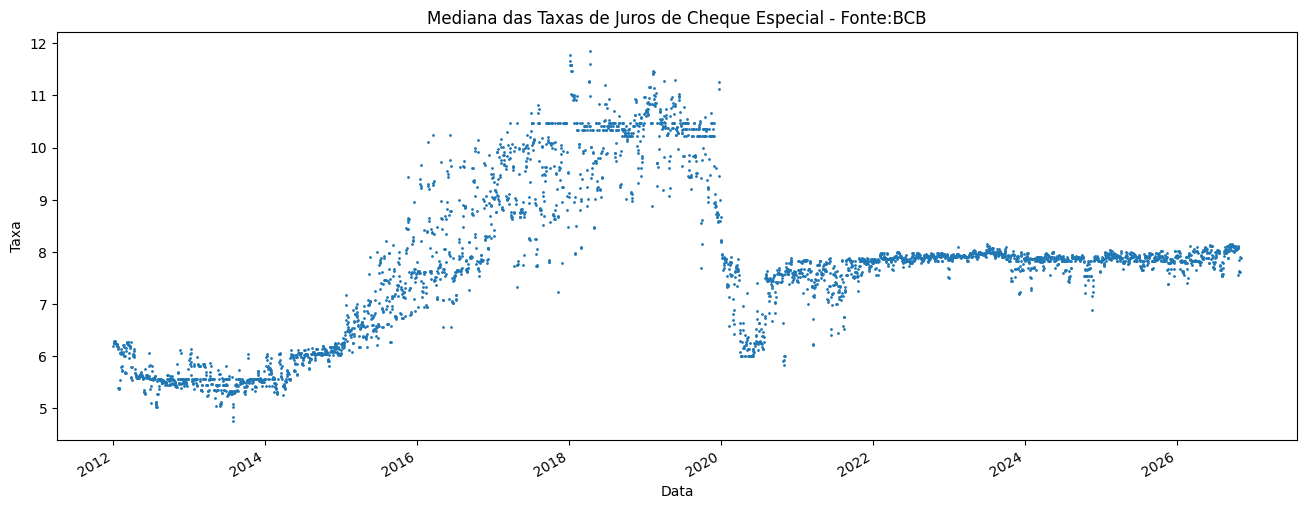

In [3]:
import pandas as pd

ep = em.get_endpoint('TaxasJurosDiariaPorInicioPeriodo')
df_cheque = (ep.query()
               .filter(ep.Segmento == 'PESSOA FÍSICA',
                       ep.Modalidade == 'Cheque especial - Prefixado')
               .collect())
grp = df_cheque.groupby('InicioPeriodo')
df_mean = grp.agg({'TaxaJurosAoMes': 'median'})

df_mean['TaxaJurosAoMes'].plot(figsize=(16,6), style='o', markersize=1,
                               xlabel='Data', ylabel='Taxa',
                               title='Mediana das Taxas de Juros de Cheque Especial - Fonte:BCB');